# List-aware EDA

Setup for the list-aware track: a listed home, and the question is what it will sell for given its list price.

Two tables:

- `listings` — 150,000 sales from January 2021 to May 2026. This is the training set. It has `list_price` and `sold_price`.
- `test_list_aware` — homes to predict. It has `list_price` and no sale outcome.

Columns that appear only on `listings` (`sold_price`, `date_sold`, `days_on_market`, `external_avm_estimate`, `external_avm_estimate_date`) are known after the sale, or are not on the test file. They are here so the training data is visible. They are not features you can read off a list-aware test row.

In [1]:
import os
import sys

if "google.colab" in sys.modules:
    if not os.path.exists("/content/SSU-Data-Dash"):
        !git clone -q https://github.com/erwinzhang7/SSU-Data-Dash.git /content/SSU-Data-Dash
    os.chdir("/content/SSU-Data-Dash")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data
from features import square_feet

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

## Load

In [2]:
listings = data.load("listings")
test = data.load("list_aware")

print(f"listings: {listings.shape[0]:,} rows, {listings.shape[1]} columns")
print(f"  listed {listings['date_listed'].min():%Y-%m-%d} to {listings['date_listed'].max():%Y-%m-%d}")
print(f"  sold   {listings['date_sold'].min():%Y-%m-%d} to {listings['date_sold'].max():%Y-%m-%d}")
print(f"test_list_aware: {test.shape[0]:,} rows, {test.shape[1]} columns")
print(f"  listed {test['date_listed'].min():%Y-%m-%d} to {test['date_listed'].max():%Y-%m-%d}")
print()
print("On the training sales only:", sorted(set(listings.columns) - set(test.columns)))

test_list_aware.parquet: reconstructing file:   0%|          |  0.00B /  937kB            

test_list_aware.parquet: downloading bytes:           |  0.00B            

listings: 150,000 rows, 22 columns
  listed 2020-02-19 to 2026-05-29
  sold   2021-01-01 to 2026-05-31
test_list_aware: 4,064 rows, 17 columns
  listed 2025-07-24 to 2026-09-28

On the training sales only: ['date_sold', 'days_on_market', 'external_avm_estimate', 'external_avm_estimate_date', 'sold_price']


## Preview

In [3]:
listings.head()

,ml_num,sold_price,list_price,date_listed,date_sold,days_on_market,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,external_avm_estimate,external_avm_estimate_date,remarks
0,SYN-0023247,364100.0,371200.0,2020-12-29,2021-01-01,3,Condo Apt,Apartment,1,1,0,0.0,622,NaN,NaN,Toronto,Sumacpark,43.602039,-79.261184,366200.0,2021-02-14,Looking For More Space In A Turnkey Condo? Thi...
1,SYN-0156988,599000.0,595800.0,2020-12-26,2021-01-01,6,Condo Apt,Apartment,2,1,0,0.0,649,NaN,NaN,Toronto,Hickorymills,43.695388,-79.510865,622800.0,2021-12-26,"Imagine a quiet evening on Sequoia Trail, wher..."
2,SYN-0087706,492900.0,462200.0,2020-12-22,2021-01-01,10,Condo Apt,Apartment,2,1,1,0.0,900-1099,NaN,NaN,North York,Hazelmills,43.740512,-79.386216,NaN,2020-12-03,"Discover this inviting 2-bedroom, 1-bath condo..."
3,SYN-0128154,532300.0,524900.0,2020-12-19,2021-01-01,13,Condo Apt,Apartment,1,1,1,0.0,876,NaN,NaN,Scarborough,Sumacbank,43.643774,-79.470180,573600.0,2021-02-22,Sumacbank presents this 1-bedroom condo on Mag...
4,SYN-0118596,564100.0,558300.0,2020-12-05,2021-01-01,27,Condo Apt,Apartment,1,1,1,0.0,514,NaN,NaN,Toronto,Ashworth,43.696172,-79.274137,513000.0,2021-02-05,"Morning coffee at the kitchen island, then a s..."


In [4]:
test.head()

,ml_num,list_price,date_listed,house_type_name,house_style,bedrooms,washrooms,parking_total,garage,house_area,lot_front,lot_depth,municipality,community,latitude,longitude,remarks
0,SYN-0120320,624700.0,2026-08-27,Condo Apt,Apartment,1,1,1,0.0,657,NaN,NaN,Etobicoke,Cedarglen,43.628228,-79.213146,Cedarglen offers this move-in-ready 1-bedroom ...
1,SYN-0041629,1370000.0,2026-03-28,Detached,2-Storey,4,2,3,0.0,1600-1799,34.00,97.26,Scarborough,Maplegrove,43.686642,-79.475803,"If your family needs room to grow, this 4-bedr..."
2,SYN-0070828,3101400.0,2026-07-22,Detached,2 1/2 Storey,3,3,2,0.0,2700,63.36,110.88,Toronto,Poplarcrest,43.648734,-79.394781,"Professionals, This Stunning 2 1/2 Storey Home..."
3,SYN-0102921,513500.0,2026-05-15,Condo Apt,Apartment,1,1,1,0.0,673,NaN,NaN,Toronto,Cypressdale,43.743930,-79.393589,Move-In Ready 1-Bedroom Plus Den In Cypressdal...
4,SYN-0096074,544400.0,2026-09-14,Condo Apt,Apartment,1,1,1,0.0,520,NaN,NaN,Toronto,Cypresspark,43.572223,-79.364242,The den in this 1-bedroom condo apartment on A...


## Summary stats

`house_area` is text (`"622"` or a range like `"900-1099"`), so it is not in `describe()`. `square_feet` below is the number, or the middle of the range. That column is derived here for the summary and the plots.

In [5]:
listings = listings.copy()
test = test.copy()
listings["square_feet"] = square_feet(listings["house_area"])
test["square_feet"] = square_feet(test["house_area"])

print("Training sales")
display(listings.describe().T.round(1))
print("List-aware test homes")
display(test.describe().T.round(1))

Training sales


,count,mean,min,25%,50%,75%,max,std
sold_price,150000.0,1073917.036,172600.0,623700.0,856650.0,1239800.0,30000000.0,812529.953536
list_price,150000.0,1074504.908667,161800.0,631700.0,859700.0,1233900.0,28078000.0,810471.62734
date_listed,150000,2023-04-16 14:02:04.992000,2020-02-19 00:00:00,2021-10-25 00:00:00,2023-03-11 00:00:00,2024-08-24 00:00:00,2026-05-29 00:00:00,NaN
date_sold,150000,2023-05-08 20:15:59.040000,2021-01-01 00:00:00,2021-11-08 00:00:00,2023-03-30 00:00:00,2024-09-28 00:00:00,2026-05-31 00:00:00,NaN
days_on_market,150000.0,22.259653,0.0,6.0,12.0,26.0,320.0,31.628163
bedrooms,150000.0,2.341673,0.0,1.0,2.0,3.0,6.0,1.106252
washrooms,150000.0,2.158313,1.0,1.0,2.0,3.0,6.0,1.109122
parking_total,150000.0,1.853387,0.0,1.0,1.0,3.0,6.0,1.647204
garage,150000.0,0.41186,0.0,0.0,0.0,1.0,6.0,0.713168
lot_front,62737.0,36.329378,10.0,22.93,32.53,46.06,150.0,17.60914


List-aware test homes


,count,mean,min,25%,50%,75%,max,std
list_price,4064.0,1010360.580709,216200.0,578600.0,816250.0,1188150.0,19126100.0,760842.420623
date_listed,4064,2026-06-22 16:40:16.535433,2025-07-24 00:00:00,2026-05-27 00:00:00,2026-06-25 00:00:00,2026-08-01 00:00:00,2026-09-28 00:00:00,NaN
bedrooms,4064.0,2.416831,0.0,2.0,2.0,3.0,6.0,1.113085
washrooms,4064.0,2.184301,1.0,1.0,2.0,3.0,6.0,1.114529
parking_total,4064.0,1.95128,0.0,1.0,1.0,3.0,6.0,1.699296
garage,4064.0,0.468258,0.0,0.0,0.0,1.0,6.0,0.744808
lot_front,1909.0,36.380927,10.0,22.7,31.88,45.99,127.05,18.138679
lot_depth,1909.0,118.266307,40.0,97.64,116.15,135.31,282.88,29.872057
latitude,4064.0,43.642554,43.490267,43.599992,43.640271,43.679285,43.836356,0.055412
longitude,4064.0,-79.378969,-79.585263,-79.447012,-79.391386,-79.313777,-79.086243,0.101527


## Missing data

`lot_front` and `lot_depth` are empty for homes without a lot. The last table checks that against property type. `external_avm_estimate` is missing on a small share of training sales, and the whole estimate is absent from the test file.

In [6]:
def missing_table(df):
    missing = df.isna().sum()
    table = pd.DataFrame({
        "missing": missing,
        "percent": (100 * missing / len(df)).round(2),
    })
    return table.sort_values(["percent", "missing"], ascending=False)

print("Training sales")
display(missing_table(listings))
print("List-aware test homes")
display(missing_table(test))

Training sales


,missing,percent
lot_front,87263,58.18
lot_depth,87263,58.18
external_avm_estimate,1306,0.87
ml_num,0,0.00
sold_price,0,0.00
list_price,0,0.00
date_listed,0,0.00
date_sold,0,0.00
days_on_market,0,0.00
house_type_name,0,0.00


List-aware test homes


,missing,percent
lot_front,2155,53.03
lot_depth,2155,53.03
ml_num,0,0.00
list_price,0,0.00
date_listed,0,0.00
house_type_name,0,0.00
house_style,0,0.00
bedrooms,0,0.00
washrooms,0,0.00
parking_total,0,0.00


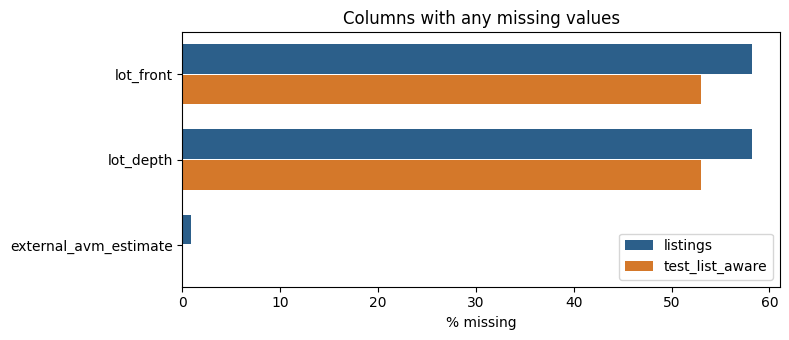

,% missing lot_front
house_type_name,
Co-Op Apt,100.0
Condo Apt,100.0
Condo Townhouse,100.0
Detached,0.0
Freehold Townhouse,0.0
Semi-Detached,0.0


In [7]:
train_pct = 100 * listings.isna().mean()
test_pct = 100 * test.isna().mean()
columns = sorted(set(train_pct[train_pct > 0].index) | set(test_pct[test_pct > 0].index))

fig, ax = plt.subplots(figsize=(8, 3.5))
y = np.arange(len(columns))
ax.barh(y + 0.18, [train_pct.get(c, 0) for c in columns], height=0.35, label="listings", color="#2c5f8a")
ax.barh(y - 0.18, [test_pct.get(c, 0) for c in columns], height=0.35, label="test_list_aware", color="#d4782a")
ax.set_yticks(y)
ax.set_yticklabels(columns)
ax.set_xlabel("% missing")
ax.set_title("Columns with any missing values")
ax.legend()
fig.tight_layout()
plt.show()

lot_missing = (
    listings.groupby("house_type_name")["lot_front"]
    .apply(lambda s: round(100 * s.isna().mean(), 1))
    .rename("% missing lot_front")
    .sort_values(ascending=False)
)
lot_missing.to_frame()

## Distributions of numeric columns

Count columns (`bedrooms`, `washrooms`, `parking_total`, `garage`) use one bin per integer. Other columns are drawn from the 0.5th to the 99.5th percentile so a few extreme prices do not flatten the rest of the histogram. The printed max still includes those extremes.

The test plot uses only columns that exist at prediction time, plus `square_feet`.

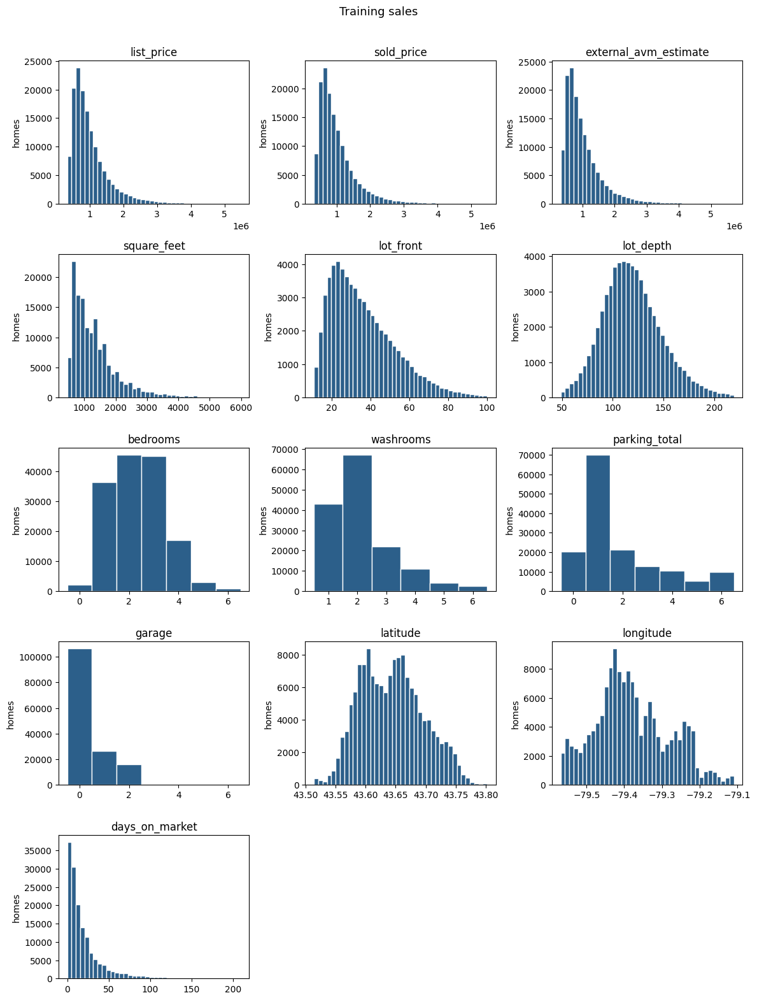

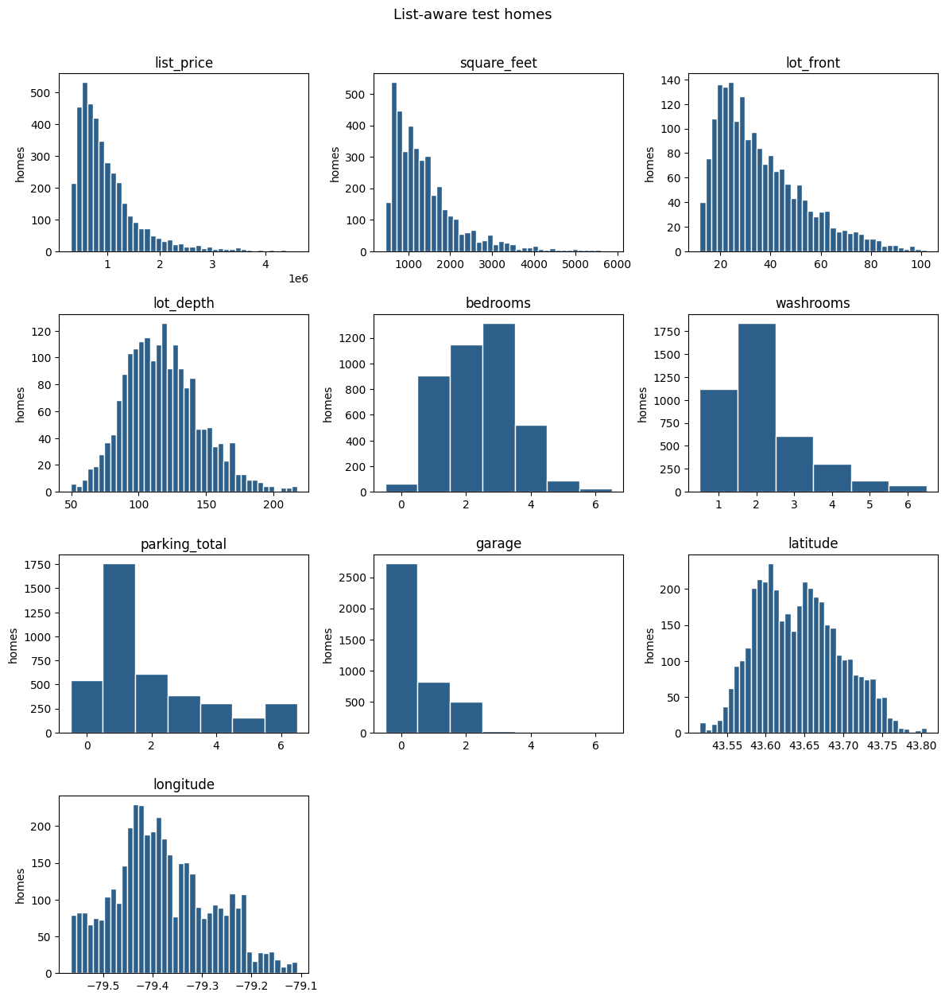

In [8]:
COUNT_COLUMNS = ["bedrooms", "washrooms", "parking_total", "garage"]
COLUMN_ORDER = [
    "list_price", "sold_price", "external_avm_estimate",
    "square_feet", "lot_front", "lot_depth",
    "bedrooms", "washrooms", "parking_total", "garage",
    "latitude", "longitude",
    "days_on_market",
]

def plot_distributions(df, title):
    columns = [c for c in COLUMN_ORDER if c in df.columns]
    columns += [c for c in df.select_dtypes(include="number").columns if c not in columns]
    ncols = 3
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 3.1 * nrows))
    axes = np.atleast_1d(axes).ravel()

    for ax, column in zip(axes, columns):
        values = df[column].dropna()
        if column in COUNT_COLUMNS:
            bins = np.arange(values.min() - 0.5, values.max() + 1.5, 1)
            ax.hist(values, bins=bins, color="#2c5f8a", edgecolor="white")
        else:
            lo, hi = values.quantile([0.005, 0.995])
            shown = values[(values >= lo) & (values <= hi)]
            ax.hist(shown, bins=40, color="#2c5f8a", edgecolor="white")
        ax.set_title(column)
        ax.set_ylabel("homes")

    for ax in axes[len(columns):]:
        ax.axis("off")
    fig.suptitle(title, y=1.01, fontsize=13)
    fig.tight_layout()
    plt.show()

plot_distributions(listings, "Training sales")
plot_distributions(test, "List-aware test homes")

## Transforms for the list-aware models

Skew of the numeric columns in the histograms above. A skew near 0 is symmetric. `notebooks/list_aware_models.ipynb` uses the transforms in the last column. Medians and indicators are computed from sales before December 2025 only, so the validation months do not enter the transform.

| Column | Skew | Skew of the log | What the model does |
|---|---:|---:|---|
| `sold_price` | 5.04 | 0.80 | Log. This is the regression target. |
| `list_price` | 5.07 | 0.82 | Log. |
| `square_feet` | 2.90 | 0.60 | Log. Parsed from `house_area`. |
| `lot_front` | 1.19 | 0.02 | Log, plus a missing indicator. |
| `lot_depth` | 0.61 | −0.38 | Left in feet. The log bends it the other way. |
| `bedrooms` | 0.37 | | Unchanged. |
| `washrooms` | 1.26 | | Unchanged. The skew is a pile of 1s and 2s, not a long tail. |
| `parking_total` | 1.21 | | Unchanged. Same reason, and the value can be 0. |
| `garage` | 1.69 | | Unchanged. Same reason, and the value can be 0. |
| `latitude`, `longitude` | 0.28, 0.37 | | Unchanged. |

`lot_front` and `lot_depth` are missing together on 58% of rows, the homes without a lot. Those rows stay in the model: the indicator is 1 and log lot front is 0.

`days_on_market` (skew 4.22) and `external_avm_estimate` (skew 4.95) are skewed too. Neither column is on the list-aware test file, so the models leave them out.

The log of price is still mildly right-skewed (0.80) because of the expensive tail. It is the scale the linear model uses.

## Sold price compared with list price

Percent above list is `(sold_price - list_price) / list_price`. Positive means the home sold for more than its asking price. The test file has no sold price, so these charts use the training sales only.

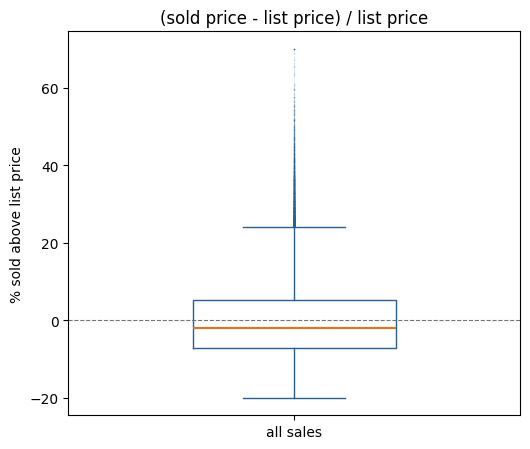

median -2.0%,  mean +0.2%,  standard deviation 10.7 percentage points


In [9]:
pct = 100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"]

fig, ax = plt.subplots(figsize=(5.4, 4.6))
ax.boxplot(
    pct,
    tick_labels=["all sales"],
    widths=0.45,
    flierprops=dict(marker=".", markersize=2, alpha=0.12, markeredgecolor="none", markerfacecolor="#2c5f8a"),
    medianprops=dict(color="#d4782a", linewidth=1.6),
    boxprops=dict(color="#2c5f8a"),
    whiskerprops=dict(color="#2c5f8a"),
    capprops=dict(color="#2c5f8a"),
)
ax.axhline(0, color="0.45", lw=0.8, ls="--")
ax.set_ylabel("% sold above list price")
ax.set_title("(sold price - list price) / list price")
fig.tight_layout()
plt.show()

print(
    f"median {pct.median():+.1f}%,  mean {pct.mean():+.1f}%,  "
    f"standard deviation {pct.std():.1f} percentage points"
)

### Over time

The line is the average percent above list in each sale month. The band is that average plus and minus one standard deviation of the homes sold that month.

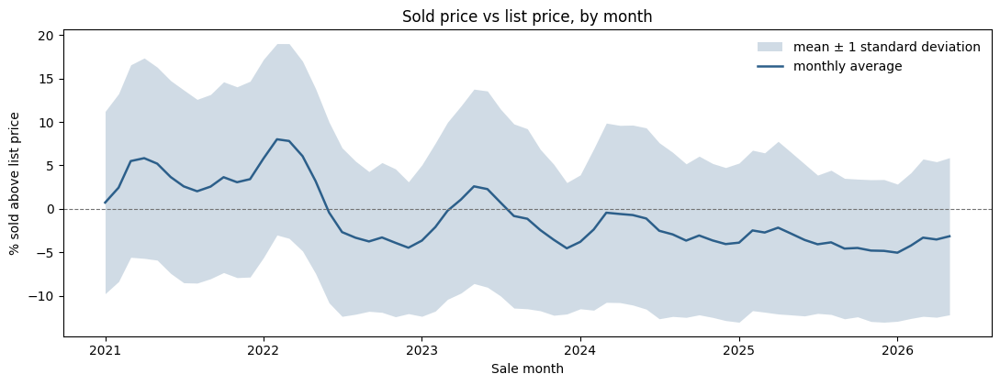

In [10]:
pct = 100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"]
by_month = pct.groupby(listings["date_sold"].dt.to_period("M"))
mean = by_month.mean()
std = by_month.std()
x = mean.index.to_timestamp()

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.fill_between(
    x, mean - std, mean + std,
    color="#2c5f8a", alpha=0.22, linewidth=0,
    label="mean ± 1 standard deviation",
)
ax.plot(x, mean, color="#2c5f8a", lw=1.8, label="monthly average")
ax.axhline(0, color="0.45", lw=0.8, ls="--")
ax.set_ylabel("% sold above list price")
ax.set_xlabel("Sale month")
ax.set_title("Sold price vs list price, by month")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### List price vs sold price

The orange line is a sale exactly at the asking price. Axes stop at the 99.5th percentile so a few sales in the tens of millions do not compress the rest of the cloud.

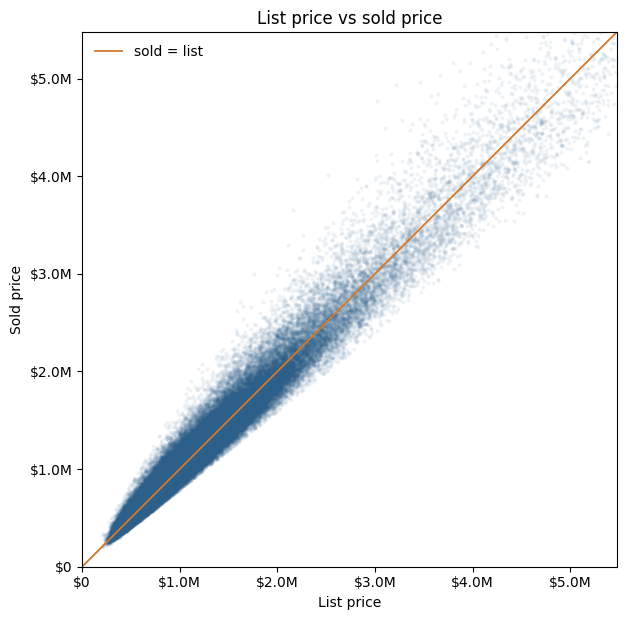

Axes stop at $5,474,205. 858 homes sit beyond that and are not drawn.
Correlation of list price and sold price: 0.986


In [11]:
limit = listings[["list_price", "sold_price"]].stack().quantile(0.995)
shown = listings[(listings["list_price"] <= limit) & (listings["sold_price"] <= limit)]

fig, ax = plt.subplots(figsize=(6.5, 6.3))
ax.scatter(
    shown["list_price"], shown["sold_price"],
    s=8, alpha=0.08, c="#2c5f8a", linewidths=0, rasterized=True,
)
ax.plot([0, limit], [0, limit], color="#d4782a", lw=1.3, label="sold = list")
ax.set_xlim(0, limit)
ax.set_ylim(0, limit)
ax.set_aspect("equal", adjustable="box")

def millions(value, _pos):
    if value == 0:
        return "$0"
    return f"${value / 1_000_000:.1f}M"

ax.xaxis.set_major_formatter(plt.FuncFormatter(millions))
ax.yaxis.set_major_formatter(plt.FuncFormatter(millions))
ax.set_xlabel("List price")
ax.set_ylabel("Sold price")
ax.set_title("List price vs sold price")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

outside = len(listings) - len(shown)
print(f"Axes stop at ${limit:,.0f}. {outside:,} homes sit beyond that and are not drawn.")
print(f"Correlation of list price and sold price: {listings['list_price'].corr(listings['sold_price']):.3f}")

## Where sales happened

Latitude and longitude are synthetic, so this does not line up with a real street map. Each point is one sale. Color is that sale's sold price on a continuous scale, not a median and not a set of bins.

Drag to move around. Scroll to zoom. The bar at the top right of the plot can switch between pan and box-zoom, or reset the view. A degree of longitude is drawn at 0.72 times a degree of latitude.

The color scale runs from the 2nd to the 98th percentile of sold price. A handful of sales near the tens of millions would otherwise pin one end of the scale and paint almost every other home the same color. Hover still shows the actual sold price.

In [12]:
import plotly.graph_objects as go

lo, hi = listings["sold_price"].quantile([0.02, 0.98])
custom = listings[["sold_price", "list_price", "house_type_name"]].to_numpy()

fig = go.Figure(
    go.Scattergl(
        x=listings["longitude"],
        y=listings["latitude"],
        mode="markers",
        marker=dict(
            size=4,
            color=listings["sold_price"],
            colorscale="Viridis",
            cmin=lo,
            cmax=hi,
            opacity=0.55,
            colorbar=dict(title="Sold price", tickprefix="$", tickformat=",.0f"),
        ),
        customdata=custom,
        hovertemplate=(
            "Sold price: %{customdata[0]:$,.0f}<br>"
            "List price: %{customdata[1]:$,.0f}<br>"
            "%{customdata[2]}<br>"
            "lat %{y:.4f}, lon %{x:.4f}<extra></extra>"
        ),
    )
)
fig.update_layout(
    title="Sold price by location",
    height=720,
    dragmode="pan",
    margin=dict(l=60, r=20, t=50, b=50),
    xaxis=dict(title="Longitude"),
    yaxis=dict(title="Latitude", scaleanchor="x", scaleratio=1 / 0.72),
)
fig.show(config={"scrollZoom": True, "displayModeBar": True})
print(f"Color scale: ${lo:,.0f} to ${hi:,.0f} (2nd to 98th percentile of sold price).")

Color scale: $389,500 to $3,357,308 (2nd to 98th percentile of sold price).


## Other features against list price

Each panel plots one feature against list price. The number in the title is the Spearman rank correlation on every row where that feature is present. With 150,000 sales, a very small correlation still produces a tiny p-value, so the size of the coefficient is the number to read.

Axes omit the top 0.5% of list prices, and the same tail of each continuous feature, so a few extreme values do not flatten the cloud. Bedrooms, washrooms, parking, and garage are whole numbers; those x-values are jittered a little so the points do not sit on a single line.

`external_avm_estimate` and `days_on_market` are not on the list-aware test file. Days on market is known only after the sale. The third-party estimate appears only on the training sales.

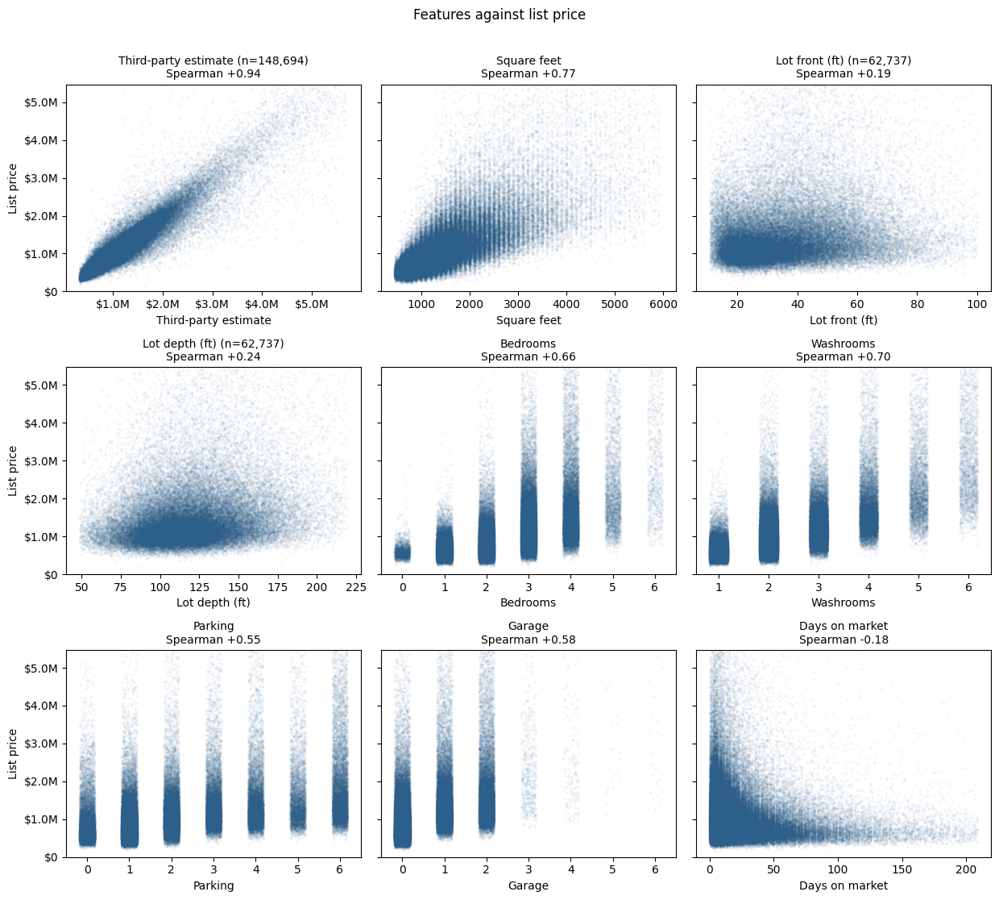

In [13]:
from scipy.stats import spearmanr

if "square_feet" not in listings.columns:
    listings["square_feet"] = square_feet(listings["house_area"])

features_vs_list = [
    ("external_avm_estimate", "Third-party estimate"),
    ("square_feet", "Square feet"),
    ("lot_front", "Lot front (ft)"),
    ("lot_depth", "Lot depth (ft)"),
    ("bedrooms", "Bedrooms"),
    ("washrooms", "Washrooms"),
    ("parking_total", "Parking"),
    ("garage", "Garage"),
    ("days_on_market", "Days on market"),
]
count_features = {"bedrooms", "washrooms", "parking_total", "garage"}
y_hi = listings["list_price"].quantile(0.995)
rng = np.random.default_rng(0)

def as_millions(value, _pos):
    if value == 0:
        return "$0"
    return f"${value / 1_000_000:.1f}M"

fig, axes = plt.subplots(3, 3, figsize=(12.5, 11), sharey=True)
for ax, (column, label) in zip(axes.ravel(), features_vs_list):
    pair = listings[[column, "list_price"]].dropna()
    rho = spearmanr(pair[column], pair["list_price"]).statistic
    keep = pair["list_price"] <= y_hi
    if column not in count_features:
        x_lo, x_hi = pair[column].quantile([0.005, 0.995])
        keep = keep & pair[column].between(x_lo, x_hi)
    shown = pair.loc[keep]
    x = shown[column].to_numpy(dtype=float)
    if column in count_features:
        x = x + rng.uniform(-0.18, 0.18, len(x))
    ax.scatter(x, shown["list_price"], s=6, alpha=0.05, c="#2c5f8a", linewidths=0, rasterized=True)
    title = f"{label}\nSpearman {rho:+.2f}"
    if len(pair) < len(listings):
        title = f"{label} (n={len(pair):,})\nSpearman {rho:+.2f}"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(label)
    if column == "external_avm_estimate":
        ax.xaxis.set_major_formatter(plt.FuncFormatter(as_millions))
    ax.set_ylim(0, y_hi)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(as_millions))

for ax in axes[:, 0]:
    ax.set_ylabel("List price")
fig.suptitle("Features against list price", y=1.01)
fig.tight_layout()
plt.show()

## Stationarity and seasonality

These checks use one number per sale month (65 months), not the 150,000 individual sales.

Two tests, read as a pair:

- **Augmented Dickey-Fuller.** The null is a unit root, meaning the level can wander and the series is not stationary. A p-value under 0.05 rejects that null.
- **KPSS.** The null is stationarity. A p-value under 0.05 rejects that null. The published table only goes from 0.01 to 0.10, so values outside that range are reported as `< 0.01` or `> 0.10`.

Each series is tested around a constant level, and again around a straight-line trend. On a short series the two tests sometimes disagree; the table says so when they do.

Seasonality is a separate question: a pattern that repeats each calendar year. A robust STL split pulls the monthly series into a trend, a 12-month seasonal piece, and a remainder. Seasonal strength is close to 1 when the seasonal piece dominates the remainder, and close to 0 when it does not. A Kruskal-Wallis test on the detrended months asks whether calendar months differ.

In [14]:
import warnings
from scipy.stats import kruskal
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss

monthly = (
    listings.assign(
        sale_month=listings["date_sold"].dt.to_period("M").dt.to_timestamp(),
        pct_vs_list=100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"],
    )
    .groupby("sale_month")
    .agg(
        median_sold=("sold_price", "median"),
        median_list=("list_price", "median"),
        mean_pct_vs_list=("pct_vs_list", "mean"),
    )
    .asfreq("MS")
)

def kpss_p(stat, pvalue, crit):
    if stat < crit["10%"]:
        return "> 0.10"
    if stat > crit["1%"]:
        return "< 0.01"
    return f"{pvalue:.3f}"

def tests_agree(adf_p, kpss_text):
    adf_rejects_unit_root = adf_p < 0.05
    kpss_rejects_stationarity = kpss_text.startswith("<") or (
        kpss_text[:1].isdigit() and float(kpss_text) < 0.05
    )
    if adf_rejects_unit_root and not kpss_rejects_stationarity:
        return "stationary"
    if (not adf_rejects_unit_root) and kpss_rejects_stationarity:
        return "not stationary"
    return "tests disagree"

rows = []
for column, label in [
    ("median_sold", "Median sold price"),
    ("median_list", "Median list price"),
    ("mean_pct_vs_list", "Mean % above list"),
]:
    series = monthly[column].dropna()
    for regression, spec in [("c", "constant level"), ("ct", "linear trend")]:
        adf_p = adfuller(series, regression=regression, autolag="AIC")[1]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            stat, pvalue, _lags, crit = kpss(series, regression=regression, nlags="auto")
        kpss_text = kpss_p(stat, pvalue, crit)
        rows.append({
            "series": label,
            "specification": spec,
            "ADF p": round(adf_p, 3),
            "KPSS p": kpss_text,
            "reading": tests_agree(adf_p, kpss_text),
        })

display(pd.DataFrame(rows))

,series,specification,ADF p,KPSS p,reading
0,Median sold price,constant level,0.580,> 0.10,tests disagree
1,Median sold price,linear trend,0.033,> 0.10,stationary
2,Median list price,constant level,0.007,> 0.10,stationary
3,Median list price,linear trend,0.175,0.024,not stationary
4,Mean % above list,constant level,0.025,< 0.01,tests disagree
5,Mean % above list,linear trend,0.001,> 0.10,stationary


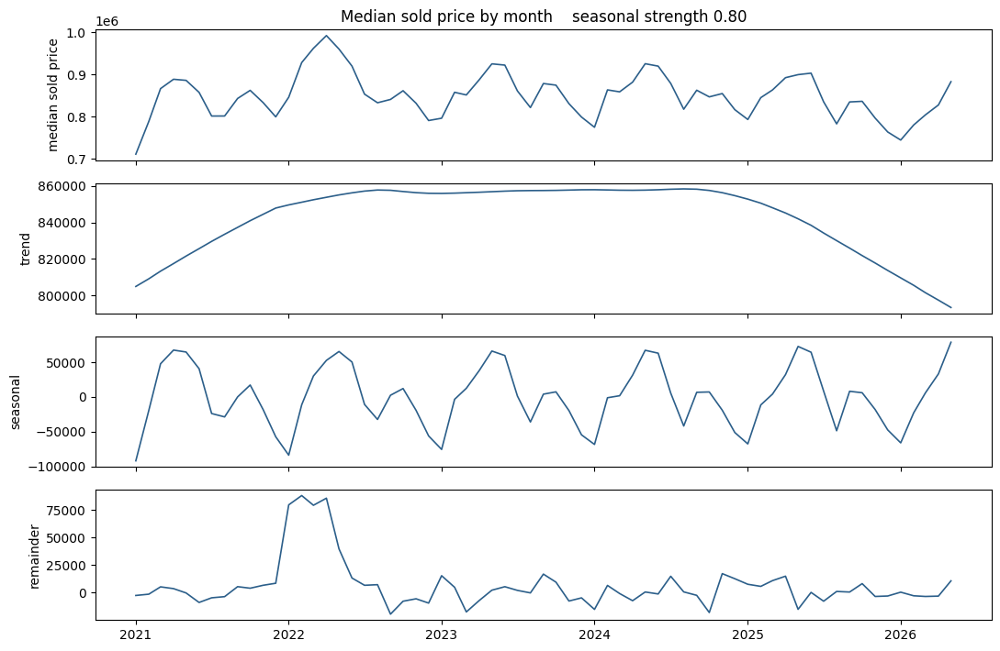

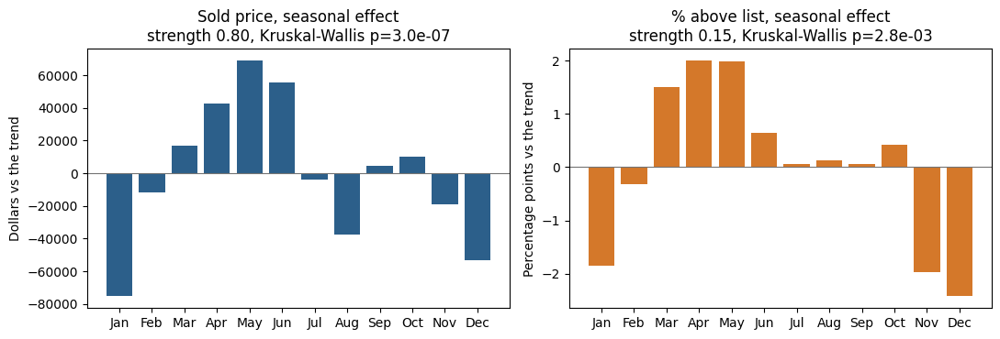

Median sold price: seasonal strength 0.80. The seasonal piece peaks in May and is lowest in Jan, a swing of $144,375 around the trend.
Mean percent above list: seasonal strength 0.15, a swing of 4.4 percentage points. The slow drift in that series is larger than the seasonal wiggle.


In [15]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

def decompose(series):
    series = series.dropna()
    fit = STL(series, period=12, robust=True).fit()
    strength = max(0.0, 1 - np.var(fit.resid) / np.var(fit.seasonal + fit.resid))
    detrended = (series - fit.trend).dropna()
    groups = [detrended[detrended.index.month == month] for month in range(1, 13)]
    _stat, pvalue = kruskal(*groups)
    effect = fit.seasonal.groupby(fit.seasonal.index.month).mean()
    return fit, strength, pvalue, effect

sold_fit, sold_strength, sold_p, sold_effect = decompose(monthly["median_sold"])
pct_fit, pct_strength, pct_p, pct_effect = decompose(monthly["mean_pct_vs_list"])

fig, axes = plt.subplots(4, 1, figsize=(11, 7.2), sharex=True)
pieces = [
    (monthly["median_sold"].dropna(), "median sold price"),
    (sold_fit.trend, "trend"),
    (sold_fit.seasonal, "seasonal"),
    (sold_fit.resid, "remainder"),
]
for ax, (values, name) in zip(axes, pieces):
    ax.plot(values.index, values, color="#2c5f8a", lw=1.2)
    ax.set_ylabel(name)
axes[0].set_title(f"Median sold price by month    seasonal strength {sold_strength:.2f}")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(MONTHS, sold_effect.values, color="#2c5f8a")
axes[0].axhline(0, color="0.45", lw=0.8)
axes[0].set_title(f"Sold price, seasonal effect\nstrength {sold_strength:.2f}, Kruskal-Wallis p={sold_p:.1e}")
axes[0].set_ylabel("Dollars vs the trend")
axes[1].bar(MONTHS, pct_effect.values, color="#d4782a")
axes[1].axhline(0, color="0.45", lw=0.8)
axes[1].set_title(f"% above list, seasonal effect\nstrength {pct_strength:.2f}, Kruskal-Wallis p={pct_p:.1e}")
axes[1].set_ylabel("Percentage points vs the trend")
fig.tight_layout()
plt.show()

peak = MONTHS[int(sold_effect.idxmax()) - 1]
trough = MONTHS[int(sold_effect.idxmin()) - 1]
swing = sold_effect.max() - sold_effect.min()
print(
    f"Median sold price: seasonal strength {sold_strength:.2f}. "
    f"The seasonal piece peaks in {peak} and is lowest in {trough}, "
    f"a swing of ${swing:,.0f} around the trend."
)
print(
    f"Mean percent above list: seasonal strength {pct_strength:.2f}, "
    f"a swing of {pct_effect.max() - pct_effect.min():.1f} percentage points. "
    f"The slow drift in that series is larger than the seasonal wiggle."
)

## How the models notebook uses this

`notebooks/list_aware_models.ipynb` does not forecast the raw price level. The regression is on log sold price, using the transforms noted beside the histograms. The time-series piece is the monthly mean of that regression's log residual on the training months.

An Augmented Dickey-Fuller test with a trend decides whether that residual is differenced. The forecast model is a one-month autoregression and a 12-month autoregression. When the residual is not differenced, the model uses a constant level. The forecast for December 2025 through May 2026 is added back to the log prediction for each home sold in that month.

## 'Remarks' column

Every training sale has a `remarks` description, and the list-aware test file has one too, so text can be used at prediction time. A typical remark is about 60 words. The descriptions share a small set of phrases even though almost every full text is unique.

The comparison below is with the "percent above list", `(sold_price - list_price) / list_price`. A link with the raw sold price mostly restates bedrooms, property type, and location, which the list price already contains.

Overall median percent above list: -1.97%


,phrase,n,pct_with,pct_without,pct_gap,sold_with,sold_without
0,parking is not,52,-5.46,-1.97,-3.49,635250.0,856800.0
1,locker,9450,-3.53,-1.85,-1.67,640750.0,880800.0
2,unobstructed,9817,-3.44,-1.85,-1.59,641000.0,882000.0
3,as is,407,-3.01,-1.97,-1.04,711400.0,857000.0
4,view,22238,-2.75,-1.82,-0.93,699400.0,892600.0
5,as-is,22206,-2.75,-1.82,-0.92,793000.0,868900.0
6,upgrade,4335,-2.37,-1.96,-0.41,743700.0,861100.0
7,original,37296,-2.26,-1.88,-0.38,811600.0,872100.0
8,older,16125,-2.28,-1.94,-0.34,830400.0,859900.0
9,good bones,4932,-2.18,-1.97,-0.21,789450.0,859100.0


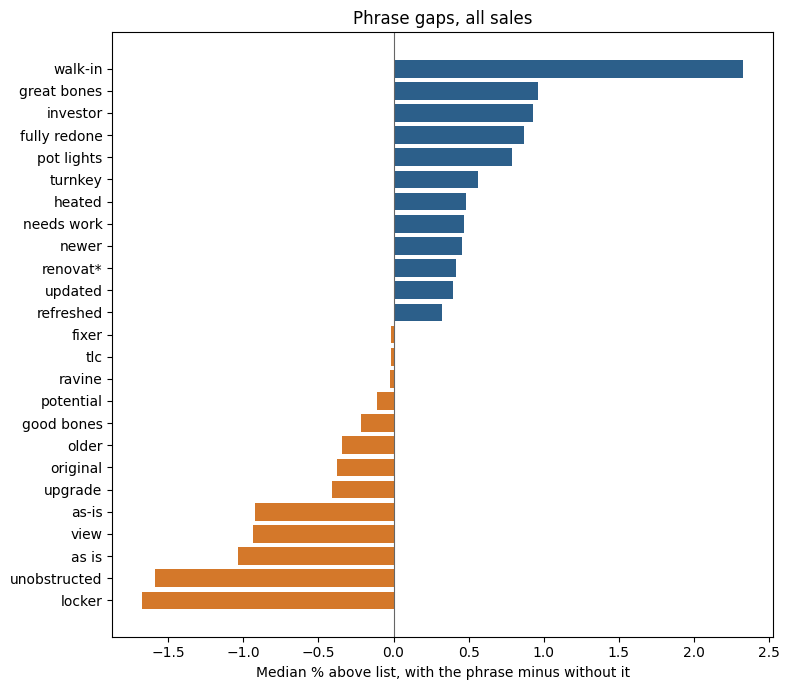

In [16]:
listings["pct_vs_list"] = (
    100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"]
)

# pattern is matched literally in the lowercased remark. "renovat" covers renovated and renovation.
PHRASES = [
    ("turnkey", "turnkey"),
    ("fully redone", "fully redone"),
    ("renovat", "renovat*"),
    ("updated", "updated"),
    ("refreshed", "refreshed"),
    ("newer", "newer"),
    ("as-is", "as-is"),
    ("as is", "as is"),
    ("good bones", "good bones"),
    ("great bones", "great bones"),
    ("potential", "potential"),
    ("original", "original"),
    ("investor", "investor"),
    ("needs work", "needs work"),
    ("tlc", "tlc"),
    ("fixer", "fixer"),
    ("upgrade", "upgrade"),
    ("older", "older"),
    ("unobstructed", "unobstructed"),
    ("view", "view"),
    ("ravine", "ravine"),
    ("parking is not", "parking is not"),
    ("locker", "locker"),
    ("walk-in", "walk-in"),
    ("pot lights", "pot lights"),
    ("heated", "heated"),
]

def phrase_table(frame, phrases):
    text = frame["remarks"].str.lower()
    rows = []
    for pattern, label in phrases:
        mask = text.str.contains(pattern, regex=False)
        n = int(mask.sum())
        if n == 0 or n == len(frame):
            med_with = med_without = gap = sold_with = sold_without = np.nan
        else:
            med_with = frame.loc[mask, "pct_vs_list"].median()
            med_without = frame.loc[~mask, "pct_vs_list"].median()
            gap = med_with - med_without
            sold_with = frame.loc[mask, "sold_price"].median()
            sold_without = frame.loc[~mask, "sold_price"].median()
        rows.append({
            "phrase": label,
            "n": n,
            "pct_with": med_with,
            "pct_without": med_without,
            "pct_gap": gap,
            "sold_with": sold_with,
            "sold_without": sold_without,
        })
    table = pd.DataFrame(rows).sort_values("pct_gap")
    return table

phrase_summary = phrase_table(listings, PHRASES)
show = phrase_summary.copy()
for column in ["pct_with", "pct_without", "pct_gap"]:
    show[column] = show[column].round(2)
for column in ["sold_with", "sold_without"]:
    show[column] = show[column].round(0)
print(f"Overall median percent above list: {listings['pct_vs_list'].median():+.2f}%")
display(show.reset_index(drop=True))

chart = phrase_summary[phrase_summary["n"] >= 200].sort_values("pct_gap")
colors = np.where(chart["pct_gap"] >= 0, "#2c5f8a", "#d4782a")
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(chart["phrase"], chart["pct_gap"], color=colors)
ax.axvline(0, color="0.4", lw=0.8)
ax.set_xlabel("Median % above list, with the phrase minus without it")
ax.set_title("Phrase gaps, all sales")
fig.tight_layout()
plt.show()

### The same phrases inside one property type

`pct_gap` above can be large because the phrase marks a condo or a house, not because of condition. "Locker" and "unobstructed" sit on cheaper homes; "walk-in" sits on more expensive ones. The table here repeats the comparison inside condo apartments only, and inside detached houses only. The "without" group is the other homes of that same type.

The chart keeps phrases that occur at least 200 times in both types.

Condo Apt: 76,374 sales, median percent above list -3.54%


,phrase,n,pct_with,pct_without,pct_gap,sold_with,sold_without
0,parking is not,47,-5.61,-3.54,-2.07,603600.0,644300.0
1,needs work,111,-4.52,-3.54,-0.99,612100.0,644400.0
2,as is,262,-4.45,-3.54,-0.91,623950.0,644500.0
3,as-is,11282,-4.29,-3.40,-0.90,609200.0,650800.0
4,potential,9818,-4.00,-3.47,-0.53,620400.0,648100.0
5,tlc,624,-3.95,-3.54,-0.41,584200.0,644800.0
6,great bones,2042,-3.91,-3.53,-0.38,630100.0,644700.0
7,original,20052,-3.81,-3.45,-0.36,630600.0,650100.0
8,older,7841,-3.76,-3.52,-0.24,621200.0,647100.0
9,ravine,9173,-3.68,-3.52,-0.16,640400.0,644800.0


Detached: 43,202 sales, median percent above list -0.49%


,phrase,n,pct_with,pct_without,pct_gap,sold_with,sold_without
0,parking is not,1,-9.16,-0.49,-8.68,876300.0,1367900.0
1,older,4898,-1.19,-0.41,-0.79,1276400.0,1381200.0
2,as-is,6429,-1.16,-0.38,-0.79,1226200.0,1393300.0
3,potential,8059,-0.80,-0.41,-0.40,1262300.0,1391300.0
4,view,2247,-0.81,-0.47,-0.34,1336900.0,1369800.0
5,walk-in,4900,-0.67,-0.46,-0.21,1354400.0,1369700.0
6,tlc,438,-0.68,-0.49,-0.19,1208450.0,1370300.0
7,good bones,1244,-0.66,-0.48,-0.18,1229150.0,1372200.0
8,needs work,107,-0.54,-0.49,-0.06,1299000.0,1368100.0
9,renovat*,7659,-0.48,-0.49,0.01,1348100.0,1372600.0


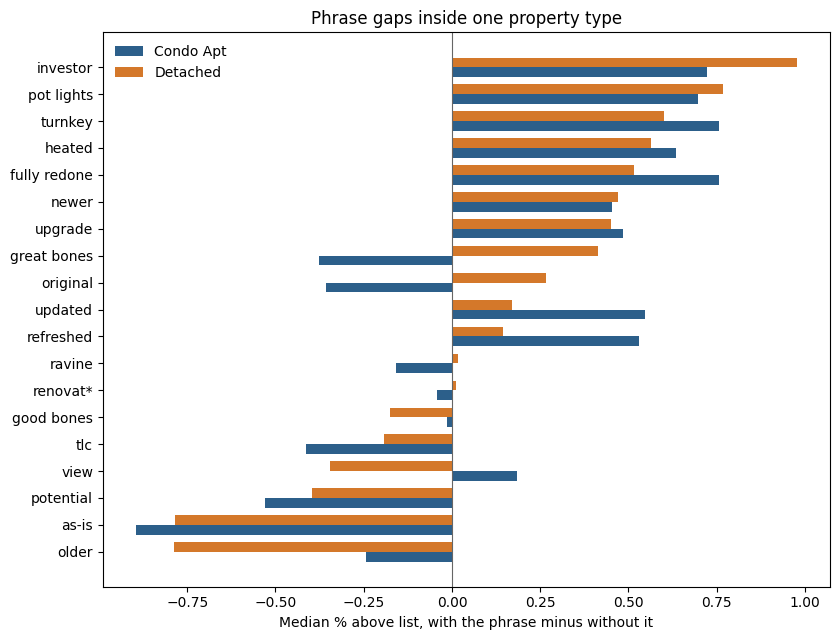

In [17]:
if "pct_vs_list" not in listings.columns:
    listings["pct_vs_list"] = (
        100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"]
    )

type_tables = {}
for kind in ["Condo Apt", "Detached"]:
    subset = listings[listings["house_type_name"] == kind]
    table = phrase_table(subset, PHRASES)
    type_tables[kind] = table
    show = table.copy()
    for column in ["pct_with", "pct_without", "pct_gap"]:
        show[column] = show[column].round(2)
    for column in ["sold_with", "sold_without"]:
        show[column] = show[column].round(0)
    print(f"{kind}: {len(subset):,} sales, median percent above list {subset['pct_vs_list'].median():+.2f}%")
    display(show.reset_index(drop=True))

both = phrase_summary[["phrase"]].drop_duplicates()
for kind, table in type_tables.items():
    kept = table.loc[table["n"] >= 200, ["phrase", "pct_gap"]].rename(columns={"pct_gap": kind})
    both = both.merge(kept, on="phrase", how="inner")
both = both.sort_values("Detached")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
y = np.arange(len(both))
ax.barh(y - 0.18, both["Condo Apt"], height=0.36, color="#2c5f8a", label="Condo Apt")
ax.barh(y + 0.18, both["Detached"], height=0.36, color="#d4782a", label="Detached")
ax.set_yticks(y)
ax.set_yticklabels(both["phrase"])
ax.axvline(0, color="0.4", lw=0.8)
ax.set_xlabel("Median % above list, with the phrase minus without it")
ax.set_title("Phrase gaps inside one property type")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

### Words and pairs of words

TF-IDF counts unigrams and bigrams. It is fit only on sales before December 2025. December 2025 through May 2026 is the holdout, the same months `run.py validate` uses. This is one split, not a refit every month.

Two views of the same words:

- Presence correlation: does a listing that contains the term sell at a different percent above list? Computed on the training months.
- A ridge model of the percent above list on the TF-IDF weights. On the holdout, the predicted percent adjusts the list price: `list price × (1 + predicted percent / 100)`. That price is compared with using the list price unchanged.

Train: 139,931 sales before December 2025
Holdout: 10,069 sales from December 2025 to May 2026


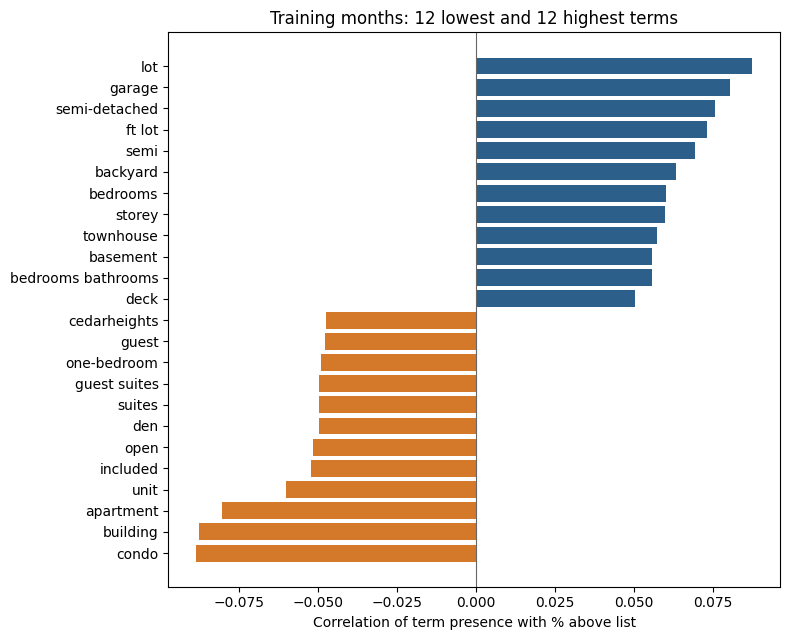

Holdout, list price unchanged: MdAPE 7.26%, MAPE 8.09%
Holdout, list price adjusted by the text model: MdAPE 7.17%, MAPE 8.03%
Change in MdAPE: -0.09 points
Approximate ridge effect when the term appears, training months.
Percentage points of the sold-versus-list gap, holding the other words in the model fixed.


,term,pct_points_when_present,listings
0,cedarheights,-5.671,591
1,aspenworth,-4.892,749
2,chestnutbank,-4.026,787
3,tamarackmills,-3.938,573
4,chestnutbourne,-3.777,930
5,rowanridge,-3.397,629
6,cypressglen,-3.176,442
7,poplargardens,-2.923,387
8,poplarcrest,-2.891,597
9,elmhaven,-2.688,652


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge

if "pct_vs_list" not in listings.columns:
    listings["pct_vs_list"] = (
        100 * (listings["sold_price"] - listings["list_price"]) / listings["list_price"]
    )

holdout_start = pd.Timestamp("2025-12-01")
train_mask = listings["date_sold"] < holdout_start
test_mask = ~train_mask
train = listings.loc[train_mask]
test = listings.loc[test_mask]
print(f"Train: {len(train):,} sales before {holdout_start:%B %Y}")
print(f"Holdout: {len(test):,} sales from {test['date_sold'].min():%B %Y} to {test['date_sold'].max():%B %Y}")

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    min_df=80,
    max_df=0.5,
    max_features=3000,
    sublinear_tf=True,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}(?:[-'][a-zA-Z]+)*\b",
    dtype=np.float32,
)
X_train = vectorizer.fit_transform(train["remarks"])
X_test = vectorizer.transform(test["remarks"])
terms = vectorizer.get_feature_names_out()

def sparse_pearson(matrix, values):
    values = np.asarray(values, dtype=np.float64)
    n = values.shape[0]
    sum_x = np.asarray(matrix.sum(axis=0)).ravel()
    sum_x2 = np.asarray(matrix.multiply(matrix).sum(axis=0)).ravel()
    sum_xy = np.asarray(matrix.T @ values).ravel()
    mean_x = sum_x / n
    std_x = np.sqrt(np.clip(sum_x2 / n - mean_x ** 2, 0, None))
    std_y = values.std()
    correlation = (sum_xy / n - mean_x * values.mean()) / (std_x * std_y)
    correlation[~np.isfinite(correlation)] = 0.0
    return correlation

present = X_train.copy()
present.data = np.ones_like(present.data)
presence_corr = sparse_pearson(present, train["pct_vs_list"])
order = np.argsort(presence_corr)
pick = np.concatenate([order[:12], order[-12:]])
presence_chart = pd.DataFrame({
    "term": terms[pick],
    "correlation": presence_corr[pick],
})

fig, ax = plt.subplots(figsize=(8, 6.5))
colors = np.where(presence_chart["correlation"] >= 0, "#2c5f8a", "#d4782a")
ax.barh(presence_chart["term"], presence_chart["correlation"], color=colors)
ax.axvline(0, color="0.4", lw=0.8)
ax.set_xlabel("Correlation of term presence with % above list")
ax.set_title("Training months: 12 lowest and 12 highest terms")
fig.tight_layout()
plt.show()

ridge = Ridge(alpha=2.0, solver="lsqr")
ridge.fit(X_train, train["pct_vs_list"])
predicted_pct = ridge.predict(X_test)
predicted_price = test["list_price"].to_numpy() * (1 + predicted_pct / 100)
sold = test["sold_price"].to_numpy()
list_price = test["list_price"].to_numpy()

def percentage_errors(predicted):
    absolute = 100 * np.abs(predicted - sold) / sold
    return {
        "MdAPE": float(np.median(absolute)),
        "MAPE": float(np.mean(absolute)),
    }

list_scores = percentage_errors(list_price)
text_scores = percentage_errors(predicted_price)
print("Holdout, list price unchanged: "
      f"MdAPE {list_scores['MdAPE']:.2f}%, MAPE {list_scores['MAPE']:.2f}%")
print("Holdout, list price adjusted by the text model: "
      f"MdAPE {text_scores['MdAPE']:.2f}%, MAPE {text_scores['MAPE']:.2f}%")
print(f"Change in MdAPE: {text_scores['MdAPE'] - list_scores['MdAPE']:+.2f} points")

# A raw coefficient is the change per unit of TF-IDF, and a rare word has a small TF-IDF.
# Multiply by the average TF-IDF among listings that use the term so the number is
# roughly the percentage-point shift when the term appears.
count = np.asarray((X_train > 0).sum(axis=0)).ravel()
mean_when_present = np.asarray(X_train.sum(axis=0)).ravel() / np.maximum(count, 1)
effect = ridge.coef_ * mean_when_present
effect_order = np.argsort(effect)
effect_pick = np.concatenate([effect_order[:12], effect_order[-12:]])
effects = pd.DataFrame({
    "term": terms[effect_pick],
    "pct_points_when_present": effect[effect_pick],
    "listings": count[effect_pick],
})
print("Approximate ridge effect when the term appears, training months.")
print("Percentage points of the sold-versus-list gap, holding the other words in the model fixed.")
display(effects.round(3).reset_index(drop=True))

### Topics

Ten topics from a non-negative factorization of the same training-month word weights. The factorization is fit on a sample of 20,000 training sales, then applied to the holdout. Each holdout sale gets a weight for every topic. The number on each panel is the rank correlation between that weight and the percent above list. The dashed line is the holdout's median percent above list. The points are the median inside five equal-count bins of topic weight, from low to high.

NMF iterations: 85


,topic,top words
0,original finishes,"original, finishes, clean, good, original fini..."
1,ft lot,"lot, ft lot, ft, garage, car, bedrooms, car ga..."
2,fully redone,"fully, turnkey, custom, fully redone, redone, ..."
3,offered as-is,"as-is, offered as-is, offered, needs, vision, ..."
4,located near,"enjoy, located, features, apartment, perfect, ..."
5,move-in ready,"newer, move-in, move-in ready, fresh, flooring..."
6,party room,"gym, party room, party, gym party, building, r..."
7,walk-in closet,"walk-in, walk-in closet, primary, primary bedr..."
8,living dining,"living dining, open-concept living, dining, op..."
9,stainless steel,"stainless, stainless steel, steel, steel appli..."


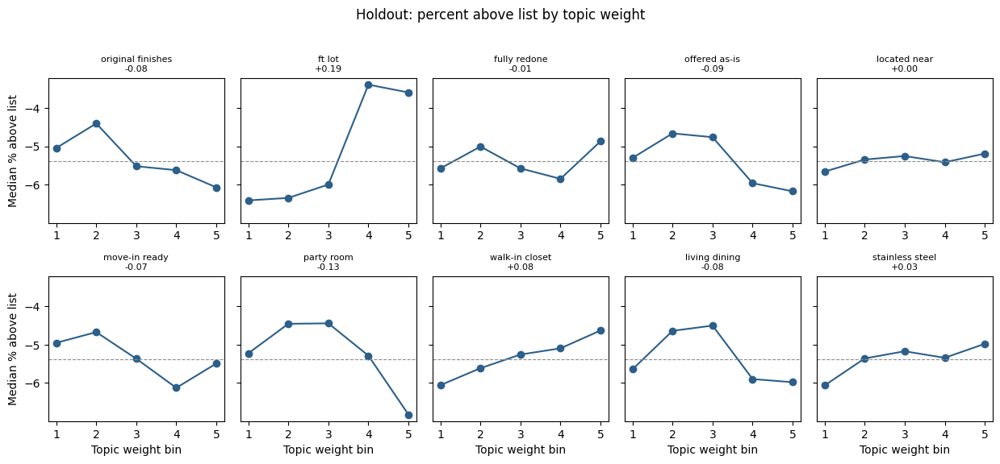

Spearman correlation of each topic with % above list, on the holdout:
  -0.126  party room
  -0.093  offered as-is
  -0.081  original finishes
  -0.077  living dining
  -0.069  move-in ready
  -0.007  fully redone
  +0.004  located near
  +0.032  stainless steel
  +0.078  walk-in closet
  +0.188  ft lot


In [19]:
from sklearn.decomposition import NMF
from scipy.stats import spearmanr

rng = np.random.default_rng(0)
sample = rng.choice(X_train.shape[0], size=20_000, replace=False)
topics = NMF(n_components=10, init="nndsvd", max_iter=200, random_state=0)
topics.fit(X_train[sample])
holdout_weights = topics.transform(X_test)
print(f"NMF iterations: {topics.n_iter_}")

def topic_label(component):
    ranked = terms[np.argsort(component)[::-1]]
    for term in ranked:
        if " " in term:
            return term
    return ranked[0]

labels = [topic_label(component) for component in topics.components_]
word_rows = []
for label, component in zip(labels, topics.components_):
    top = terms[np.argsort(component)[-8:][::-1]]
    word_rows.append({"topic": label, "top words": ", ".join(top)})
display(pd.DataFrame(word_rows))

holdout_pct = test["pct_vs_list"].to_numpy()
base = float(np.median(holdout_pct))
ranks = np.empty(10)
fig, axes = plt.subplots(2, 5, figsize=(12.5, 5.6), sharey=True)
for ax, index in zip(axes.ravel(), range(10)):
    weight = holdout_weights[:, index]
    ranks[index] = spearmanr(weight, holdout_pct).statistic
    bins = pd.qcut(pd.Series(weight).rank(method="first"), 5, labels=False)
    medians = pd.Series(holdout_pct).groupby(bins).median()
    ax.plot(np.arange(1, 6), medians.to_numpy(), marker="o", color="#2c5f8a")
    ax.axhline(base, color="0.55", lw=0.8, ls="--")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_title(f"{labels[index]}\n{ranks[index]:+.2f}", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Median % above list")
for ax in axes[1, :]:
    ax.set_xlabel("Topic weight bin")
fig.suptitle("Holdout: percent above list by topic weight", y=1.02)
fig.tight_layout()
plt.show()
print("Spearman correlation of each topic with % above list, on the holdout:")
for label, rank in sorted(zip(labels, ranks), key=lambda item: item[1]):
    print(f"  {rank:+.3f}  {label}")